# Avaluació del Model per Tipus de Trajectòria

Aquest notebook avalua el rendiment del model `TrajectoryTypeClassifier` per separat per a cada tipus de trajectòria, proporcionant:

- **Accuracy individual** per a cada tipus de trajectòria
- **Distribució de prediccions** per tipus
- **Matriu de confusió global**
- **Anàlisi d'errors més comuns**

## Funcionalitats principals:
1. Genera datasets separats per a cada tipus de trajectòria
2. Carrega el model pre-entrenat
3. Avalua el model sense entrenament addicional
4. Proporciona anàlisi detallada de rendiment

## Tipus de trajectòria avaluats:
- Random Walk
- Brownian Motion  
- Continuous Time Random Walk (CTRW)
- Fractional Brownian Motion
- Lévy Walks
- Annealed Transient Time Model (ATTM)
- Scaled Brownian Motion

In [1]:
from anomalouslib.models.model_handler import save_model, load_model, get_class_def_from_notebook
from anomalouslib.models.testing_utils import evaluate_continuous, predict_continuous
from anomalouslib.data.preprocessing import generate_classification_tensors
from anomalouslib.data.DatasetGenerator import DatasetGenerator
from anomalouslib.models.training_utils import train_model
from sklearn.preprocessing import LabelEncoder

from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn
import pandas as pd
import torch
import dill

In [ ]:
dg = DatasetGenerator(num_particules=1000)

generators = [
    ("rw", "RandomWalk", dg.generate_RandomWalk),
    ("bm", "BrownianMotion", dg.generate_BrownianMotion),
    ("ctrw", "ContinuousTimeRandomWalk", dg.generate_ContinuousTimeRandomWalk),
    ("fbm", "FractionalBrownianMotion", dg.generate_FractionalBrownianMotion),
    ("lw", "LevyWalks", dg.generate_LevyWalks),
    ("attm", "AnnealedTransitTimeModel", dg.generate_AnnealedTransitTimeModel),
    ("sbm", "ScaledBrownianMotion", dg.generate_ScaledBrownianMotion),
]

# Generem datasets separats per a cada tipus de trajectòria
trajectory_datasets = {}
for prefix, name, func in generators:
    df = func(random_params=True, num_passos=200)
    trajectory_datasets[name] = df
    print(f"Generat dataset per {name}: {len(df)} trajectòries")

print(f"\nTotal de tipus de trajectòria: {len(trajectory_datasets)}")

Generado dataset para RandomWalk: 1000 trayectorias
Generado dataset para BrownianMotion: 1000 trayectorias
Generado dataset para ContinuousTimeRandomWalk: 1000 trayectorias
Generado dataset para BrownianMotion: 1000 trayectorias
Generado dataset para ContinuousTimeRandomWalk: 1000 trayectorias


c:\Users\jmass\Documents\GitHub\TFG GEINF\AnomalousApp\venv\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


Generado dataset para FractionalBrownianMotion: 1000 trayectorias
Generado dataset para LevyWalks: 1000 trayectorias
1.5
Generado dataset para AnnealedTransitTimeModel: 1000 trayectorias
Generado dataset para ScaledBrownianMotion: 1000 trayectorias

Total de tipos de trayectoria: 7
Generado dataset para LevyWalks: 1000 trayectorias
1.5
Generado dataset para AnnealedTransitTimeModel: 1000 trayectorias
Generado dataset para ScaledBrownianMotion: 1000 trayectorias

Total de tipos de trayectoria: 7


In [ ]:
# Carregar el model entrenat
def load_model(model_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(model_path, map_location=device, pickle_module=dill)
    
    # Executar el codi font per recrear la classe
    exec(checkpoint["model_source"], globals())  # La classe es defineix en el scope global
    
    # Instanciar el model amb els seus arguments originals
    model_class = globals()[checkpoint["model_source"].split("class ")[1].split("(")[0].strip()]
    model = model_class(**checkpoint["params"])
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device)
    model.eval()
    if "le" in checkpoint and checkpoint["le"] is not None:
        return model, checkpoint["le"]
    return model

# Carregar model i label encoder
loaded_model, le = load_model("TrajectoryTypeClassifier.pth")
print("Model carregat exitosament")
print(f"Classes disponibles: {le.classes_}")

Modelo cargado exitosamente
Clases disponibles: ['ATTM' 'Brownian Motion' 'CTRW' 'Fractional Brownian Motion' 'Lévy Walk'
 'Random Walk' 'Scaled Brownian Motion']


In [ ]:
def process_trajectory_data(dataframe, trajectory_type, le):
    """
    Processa les dades d'un tipus específic de trajectòria per testing.
    Inclou mapatge automàtic de noms llargs a abreviacions del model.
    """
    import numpy as np
    
    # Mapatge de noms llargs a abreviacions que espera el model
    name_mapping = {
        "Random Walk": "Random Walk",
        "Brownian Motion": "Brownian Motion", 
        "Continuous Time Random Walk": "CTRW",
        "Fractional Brownian Motion": "Fractional Brownian Motion",
        "Lévy Walk": "Lévy Walk",
        "Annealed Transient Time Model": "ATTM",
        "Scaled Brownian Motion": "Scaled Brownian Motion"
    }
    
    # Preparar les coordenades
    coords_list = [np.stack([row[0], row[1]], axis=1) for row in dataframe['coords']]
    X = np.array(coords_list)  # Forma (n_samples, seq_length, 2)
    X_tensor = torch.tensor(X, dtype=torch.float32).permute(0, 2, 1)
    
    # Preparar les etiquetes verdaderes amb mapatge correcte
    true_labels_raw = dataframe["attributes"].apply(lambda x: x['trajectory_type'])
    true_labels = true_labels_raw.map(name_mapping)
    
    return X_tensor, true_labels

print("Funció de processament definida")

Función de procesamiento definida


In [ ]:
# Avaluar el model per a cada tipus de trajectòria
results = {}
detailed_results = {}

print("="*60)
print("AVALUACIÓ DEL MODEL PER TIPUS DE TRAJECTÒRIA")
print("="*60)

loaded_model.eval()
with torch.no_grad():
    for traj_type, dataframe in trajectory_datasets.items():
        print(f"\nAvaluant {traj_type}...")
        
        # Processar dades per aquest tipus de trajectòria
        X_tensor, true_labels = process_trajectory_data(dataframe, traj_type, le)
        
        # Fer prediccions
        outputs = loaded_model(X_tensor)
        _, predicted_indices = torch.max(outputs, 1)
        
        # Convertir índexs a noms de classes
        predicted_classes = [le.classes_[idx] for idx in predicted_indices.numpy()]
        true_classes = true_labels.tolist()
        
        # Calcular accuracy
        correct_predictions = sum(1 for true, pred in zip(true_classes, predicted_classes) if true == pred)
        total_predictions = len(true_classes)
        accuracy = correct_predictions / total_predictions
        
        # Guardar resultats
        results[traj_type] = accuracy
        detailed_results[traj_type] = {
            'accuracy': accuracy,
            'correct': correct_predictions,
            'total': total_predictions,
            'true_classes': true_classes,
            'predicted_classes': predicted_classes
        }
        
        print(f"  Accuracy: {accuracy:.4f} ({correct_predictions}/{total_predictions})")
        
        # Mostrar distribució de prediccions
        from collections import Counter
        pred_dist = Counter(predicted_classes)
        print(f"  Distribució de prediccions: {dict(pred_dist)}")

print("\n" + "="*60)
print("RESUM DE RESULTATS")
print("="*60)
for traj_type, accuracy in results.items():
    print(f"{traj_type:25}: {accuracy:.4f} ({accuracy*100:.2f}%)")

print(f"\nAccuracy promig: {sum(results.values())/len(results):.4f}")

EVALUACIÓN DEL MODELO POR TIPO DE TRAYECTORIA

Evaluando RandomWalk...


  Accuracy: 0.9980 (998/1000)
  Distribución de predicciones: {'Random Walk': 998, 'Fractional Brownian Motion': 1, 'Brownian Motion': 1}

Evaluando BrownianMotion...
  Accuracy: 0.7980 (798/1000)
  Distribución de predicciones: {'Brownian Motion': 798, 'Fractional Brownian Motion': 94, 'ATTM': 16, 'Lévy Walk': 11, 'Random Walk': 52, 'Scaled Brownian Motion': 24, 'CTRW': 5}

Evaluando ContinuousTimeRandomWalk...
  Accuracy: 0.7980 (798/1000)
  Distribución de predicciones: {'Brownian Motion': 798, 'Fractional Brownian Motion': 94, 'ATTM': 16, 'Lévy Walk': 11, 'Random Walk': 52, 'Scaled Brownian Motion': 24, 'CTRW': 5}

Evaluando ContinuousTimeRandomWalk...
  Accuracy: 0.9400 (940/1000)
  Distribución de predicciones: {'Lévy Walk': 7, 'CTRW': 940, 'Brownian Motion': 28, 'ATTM': 11, 'Scaled Brownian Motion': 14}

Evaluando FractionalBrownianMotion...
  Accuracy: 0.9400 (940/1000)
  Distribución de predicciones: {'Lévy Walk': 7, 'CTRW': 940, 'Brownian Motion': 28, 'ATTM': 11, 'Scaled Brow


ANÀLISI DETALLADA D'ERRORS


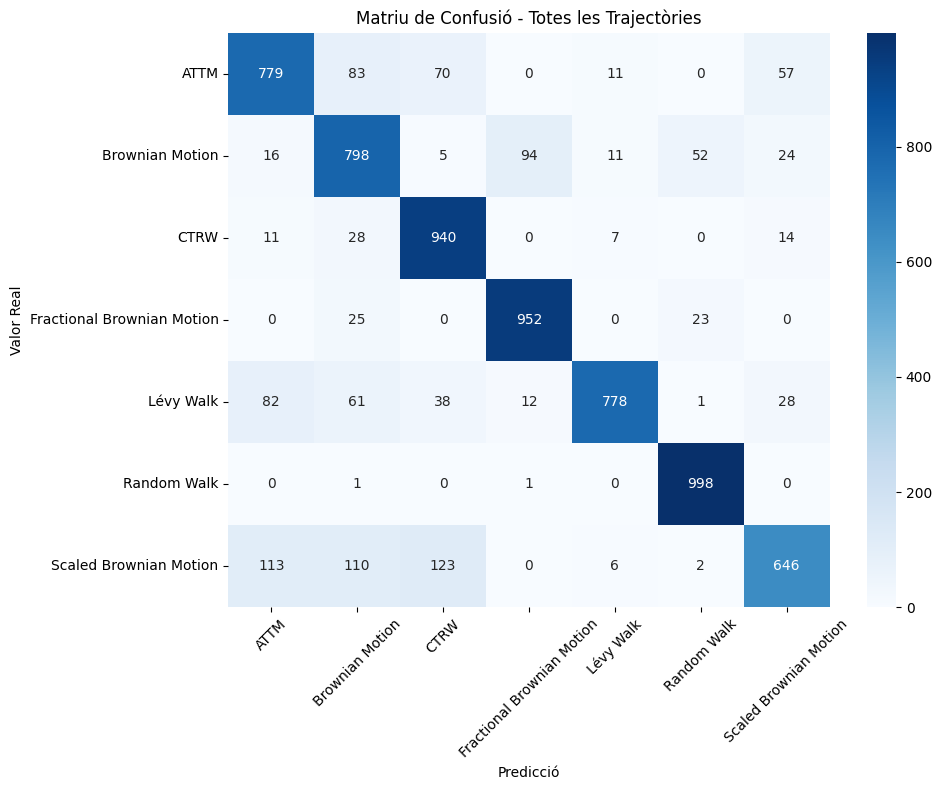


ERRORS MÉS COMUNS PER TIPUS:

RandomWalk:
  Random Walk → Fractional Brownian Motion: 1 vegades
  Random Walk → Brownian Motion: 1 vegades

BrownianMotion:
  Brownian Motion → Fractional Brownian Motion: 94 vegades
  Brownian Motion → Random Walk: 52 vegades
  Brownian Motion → Scaled Brownian Motion: 24 vegades

ContinuousTimeRandomWalk:
  CTRW → Brownian Motion: 28 vegades
  CTRW → Scaled Brownian Motion: 14 vegades
  CTRW → ATTM: 11 vegades

FractionalBrownianMotion:
  Fractional Brownian Motion → Brownian Motion: 25 vegades
  Fractional Brownian Motion → Random Walk: 23 vegades

LevyWalks:
  Lévy Walk → ATTM: 82 vegades
  Lévy Walk → Brownian Motion: 61 vegades
  Lévy Walk → CTRW: 38 vegades

AnnealedTransitTimeModel:
  ATTM → Brownian Motion: 83 vegades
  ATTM → CTRW: 70 vegades
  ATTM → Scaled Brownian Motion: 57 vegades

ScaledBrownianMotion:
  Scaled Brownian Motion → CTRW: 123 vegades
  Scaled Brownian Motion → ATTM: 113 vegades
  Scaled Brownian Motion → Brownian Motion: 110

In [14]:
# Anàlisi detallada d'errors
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

print("\n" + "="*60)
print("ANÀLISI DETALLADA D'ERRORS")
print("="*60)

# Crear matriu de confusió global
all_true = []
all_pred = []
for traj_type, details in detailed_results.items():
    all_true.extend(details['true_classes'])
    all_pred.extend(details['predicted_classes'])

# Matriu de confusió
cm = confusion_matrix(all_true, all_pred, labels=le.classes_)

# Visualitzar matriu de confusió
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matriu de Confusió - Totes les Trajectòries')
plt.xlabel('Predicció')
plt.ylabel('Valor Real')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Mostrar errors més comuns per cada tipus
print("\nERRORS MÉS COMUNS PER TIPUS:")
for traj_type, details in detailed_results.items():
    true_classes = details['true_classes']
    predicted_classes = details['predicted_classes']
    
    errors = []
    for true, pred in zip(true_classes, predicted_classes):
        if true != pred:
            errors.append(f"{true} → {pred}")
    
    if errors:
        from collections import Counter
        error_counts = Counter(errors)
        print(f"\n{traj_type}:")
        for error, count in error_counts.most_common(3):
            print(f"  {error}: {count} vegades")
    else:
        print(f"\n{traj_type}: Sense errors (100% accuracy!)")


GRÀFIC D'ACCURACY PER TIPUS DE TRAJECTÒRIA


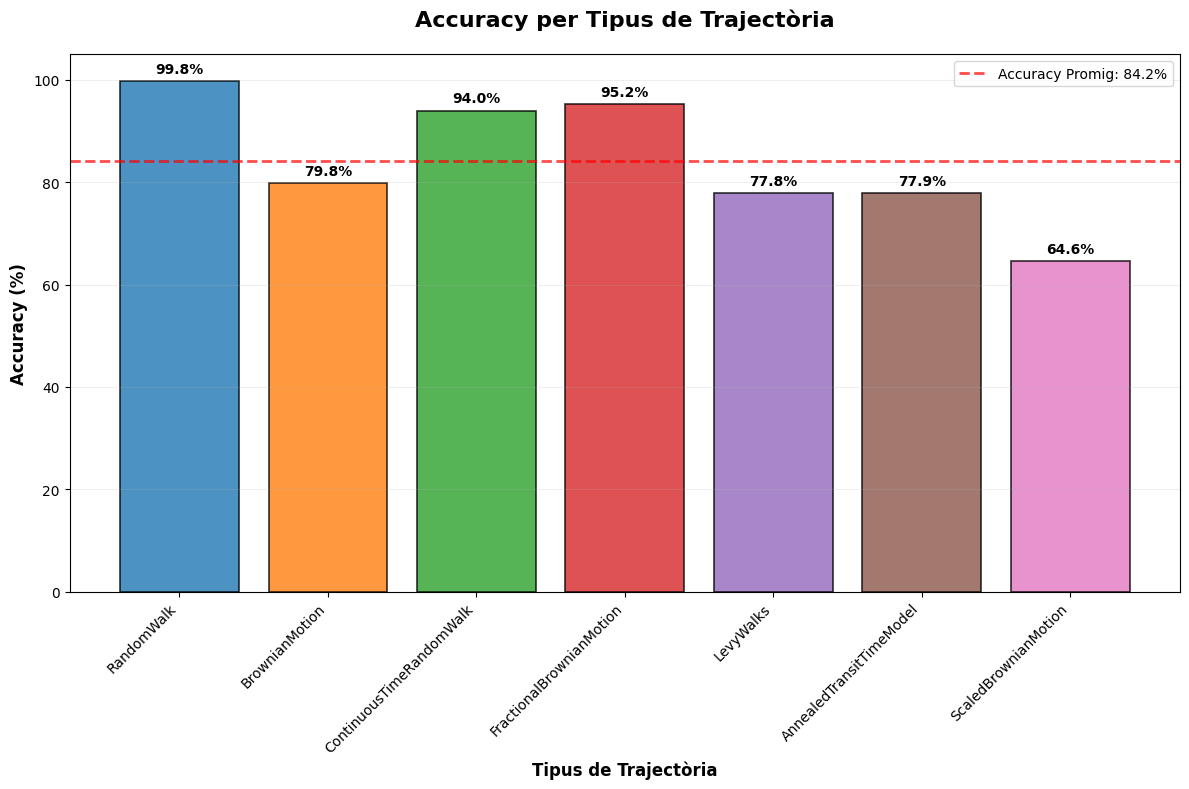


📊 ESTADÍSTIQUES:
Millor rendiment: RandomWalk (99.8%)
Pitjor rendiment: ScaledBrownianMotion (64.6%)
Diferència màxima: 35.2 punts percentuals
Desviació estàndard: 11.6%


In [16]:
# Gràfic d'accuracies per tipus de trajectòria
print("\n" + "="*60)
print("GRÀFIC D'ACCURACY PER TIPUS DE TRAJECTÒRIA")
print("="*60)

# Preparar dades per al gràfic
trajectory_names = list(results.keys())
accuracies = [results[traj] * 100 for traj in trajectory_names]  # Convertir a percentatges

# Crear el gràfic de barres
plt.figure(figsize=(12, 8))
bars = plt.bar(range(len(trajectory_names)), accuracies, 
               color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2'],
               alpha=0.8, edgecolor='black', linewidth=1.2)

# Personalitzar el gràfic
plt.title('Accuracy per Tipus de Trajectòria', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Tipus de Trajectòria', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
plt.xticks(range(len(trajectory_names)), trajectory_names, rotation=45, ha='right')
plt.ylim(0, 105)

# Afegir valors a les barres
for i, (bar, acc) in enumerate(zip(bars, accuracies)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
             f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)

# Afegir línia de l'accuracy promig
avg_accuracy = sum(accuracies) / len(accuracies)
plt.axhline(y=avg_accuracy, color='red', linestyle='--', linewidth=2, alpha=0.7,
            label=f'Accuracy Promig: {avg_accuracy:.1f}%')

# Afegir grid i llegenda
plt.grid(axis='y', alpha=0.3, linestyle='-', linewidth=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Mostrar estadístiques addicionals
print(f"\n📊 ESTADÍSTIQUES:")
print(f"Millor rendiment: {max(trajectory_names, key=lambda x: results[x])} ({max(accuracies):.1f}%)")
print(f"Pitjor rendiment: {min(trajectory_names, key=lambda x: results[x])} ({min(accuracies):.1f}%)")
print(f"Diferència màxima: {max(accuracies) - min(accuracies):.1f} punts percentuals")
print(f"Desviació estàndard: {np.std(accuracies):.1f}%")

In [ ]:
# Anàlisi de difusivitat (α) usant Mean Squared Displacement
print("\n" + "="*60)
print("ANÀLISI DE DIFUSIVITAT (α) MITJANÇANT MSD")
print("="*60)

def calculate_msd_alpha(trajectory):
    """
    Calcula el Mean Squared Displacement i l'exponent α (difusivitat) d'una trajectòria.
    MSD(τ) ∝ τ^α, on α indica el tipus de difusió.
    """
    x, y = trajectory[:, 0], trajectory[:, 1]
    n = len(x)
    
    # Calcular MSD per diferents lag times
    max_lag = min(n // 4, 50)  # Limitar el lag màxim per estabilitat
    lags = np.arange(1, max_lag + 1)
    msd_values = []
    
    for lag in lags:
        # Calcular el desplaçament quadràtic mitjà per aquest lag
        dx = x[lag:] - x[:-lag]
        dy = y[lag:] - y[:-lag]
        msd = np.mean(dx**2 + dy**2)
        msd_values.append(msd)
    
    # Ajustar MSD = A * τ^α en escala log-log per obtenir α
    # log(MSD) = log(A) + α * log(τ)
    log_lags = np.log(lags)
    log_msd = np.log(msd_values)
    
    # Regressió lineal en escala log-log
    alpha, log_A = np.polyfit(log_lags, log_msd, 1)
    
    return alpha, msd_values, lags

# Calcular α per cada tipus de trajectòria
alpha_results = {}
msd_data = {}

for traj_type, dataframe in trajectory_datasets.items():
    print(f"\nAnalitzant {traj_type}...")
    
    alphas = []
    # Analitzar una mostra de trajectòries per obtenir estadístiques
    sample_size = min(100, len(dataframe))
    sample_indices = np.random.choice(len(dataframe), sample_size, replace=False)
    
    for idx in sample_indices:
        coords = dataframe.iloc[idx]['coords']
        trajectory = np.column_stack([coords[0], coords[1]])
        
        try:
            alpha, msd_vals, lags = calculate_msd_alpha(trajectory)
            alphas.append(alpha)
        except:
            continue  # Saltar trajectòries problemàtiques
    
    if alphas:
        mean_alpha = np.mean(alphas)
        std_alpha = np.std(alphas)
        
        alpha_results[traj_type] = {
            'mean_alpha': mean_alpha,
            'std_alpha': std_alpha,
            'alphas': alphas
        }
        
        print(f"  α promig: {mean_alpha:.3f} ± {std_alpha:.3f}")
        print(f"  Nombre de trajectòries analitzades: {len(alphas)}")
        
        # Interpretació de l'α
        if mean_alpha < 0.8:
            diffusion_type = "Subdifusió"
        elif 0.8 <= mean_alpha <= 1.2:
            diffusion_type = "Difusió normal"
        else:
            diffusion_type = "Superdifusió"
        print(f"  Tipus de difusió: {diffusion_type}")
    else:
        print(f"  Error: No s'han pogut analitzar trajectòries")

print("\n" + "="*50)
print("RESUM DE COEFICIENTS α:")
print("="*50)
for traj_type, data in alpha_results.items():
    print(f"{traj_type:25}: α = {data['mean_alpha']:.3f} ± {data['std_alpha']:.3f}")

# Valors teòrics esperats per referència
theoretical_alphas = {
    'RandomWalk': 1.0,
    'BrownianMotion': 1.0,
    'ContinuousTimeRandomWalk': '<1.0 (subdifusió)',
    'FractionalBrownianMotion': 'Variable (depèn de H)',
    'LevyWalks': '>1.0 (superdifusió)',
    'AnnealedTransitTimeModel': '<1.0 (subdifusió)',
    'ScaledBrownianMotion': 'Variable'
}

print(f"\n📚 VALORS TEÒRICS ESPERATS:")
for traj_type, expected in theoretical_alphas.items():
    print(f"{traj_type:25}: {expected}")


ANÁLISIS DE DIFUSIVIDAD (α) MEDIANTE MSD

Analizando RandomWalk...
  α promedio: 0.976 ± 0.127
  Número de trayectorias analizadas: 100
  Tipo de difusión: Difusión normal

Analizando BrownianMotion...
  α promedio: 0.965 ± 0.148
  Número de trayectorias analizadas: 100
  Tipo de difusión: Difusión normal

Analizando ContinuousTimeRandomWalk...
  α promedio: 0.997 ± 0.142
  Número de trayectorias analizadas: 100
  Tipo de difusión: Difusión normal

Analizando FractionalBrownianMotion...
  α promedio: 1.010 ± 0.444
  Número de trayectorias analizadas: 100
  Tipo de difusión: Difusión normal

Analizando LevyWalks...
  α promedio: 0.942 ± 0.153
  Número de trayectorias analizadas: 100
  Tipo de difusión: Difusión normal

Analizando AnnealedTransitTimeModel...
  α promedio: 0.963 ± 0.159
  Número de trayectorias analizadas: 100
  Tipo de difusión: Difusión normal

Analizando ScaledBrownianMotion...
  α promedio: 0.993 ± 0.141
  Número de trayectorias analizadas: 100
  Tipo de difusión: Di


CORRELACIÓN ENTRE DIFUSIVIDAD (α) Y ACCURACY DEL MODELO


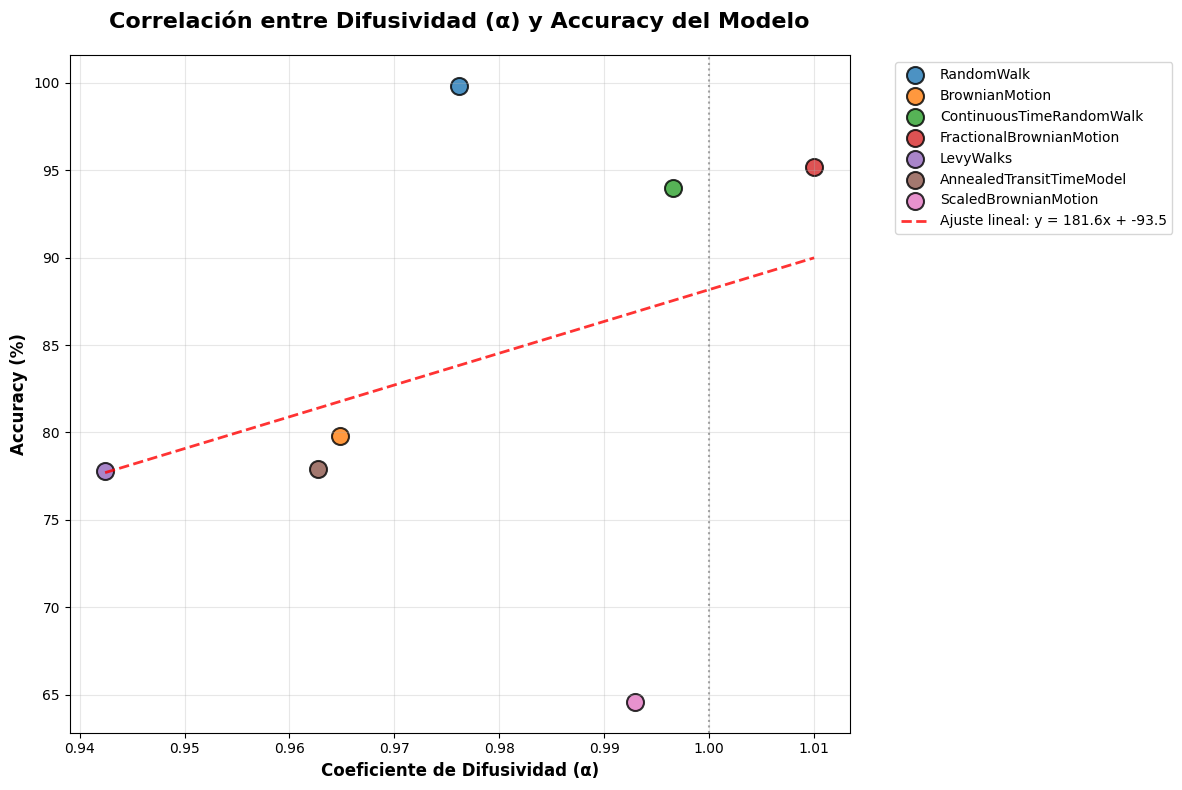


📊 ESTADÍSTICAS DE CORRELACIÓN:
Coeficiente de correlación de Pearson: 0.338
Interpretación: Correlación moderada positiva

🔍 ANÁLISIS POR TIPO DE DIFUSIÓN:
Difusión normal (0.8 ≤ α ≤ 1.2): 7 tipos, Accuracy promedio: 84.2%
  - RandomWalk: 99.8%
  - BrownianMotion: 79.8%
  - ContinuousTimeRandomWalk: 94.0%
  - FractionalBrownianMotion: 95.2%
  - LevyWalks: 77.8%
  - AnnealedTransitTimeModel: 77.9%
  - ScaledBrownianMotion: 64.6%


In [ ]:
# Correlació entre difusivitat (α) i accuracy del model
print("\n" + "="*60)
print("CORRELACIÓ ENTRE DIFUSIVITAT (α) I ACCURACY DEL MODEL")
print("="*60)

# Preparar dades per l'anàlisi de correlació
trajectory_names_corr = []
mean_alphas = []
accuracies_corr = []

for traj_type in alpha_results.keys():
    if traj_type in results:
        trajectory_names_corr.append(traj_type)
        mean_alphas.append(alpha_results[traj_type]['mean_alpha'])
        accuracies_corr.append(results[traj_type] * 100)

# Crear gràfic de dispersió α vs Accuracy
plt.figure(figsize=(12, 8))

# Scatter plot
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
for i, (name, alpha, acc) in enumerate(zip(trajectory_names_corr, mean_alphas, accuracies_corr)):
    plt.scatter(alpha, acc, s=150, c=colors[i % len(colors)], 
                alpha=0.8, edgecolors='black', linewidth=1.5, label=name)

# Ajust lineal
if len(mean_alphas) > 2:
    z = np.polyfit(mean_alphas, accuracies_corr, 1)
    p = np.poly1d(z)
    x_line = np.linspace(min(mean_alphas), max(mean_alphas), 100)
    plt.plot(x_line, p(x_line), 'r--', alpha=0.8, linewidth=2, label=f'Ajust lineal: y = {z[0]:.1f}x + {z[1]:.1f}')

# Personalitzar el gràfic
plt.title('Correlació entre Difusivitat (α) i Accuracy del Model', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Coeficient de Difusivitat (α)', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Afegir línies de referència per tipus de difusió
plt.axvline(x=1.0, color='gray', linestyle=':', alpha=0.7, label='α = 1 (Difusió normal)')
plt.tight_layout()
plt.show()

# Calcular correlació de Pearson
if len(mean_alphas) > 2:
    correlation = np.corrcoef(mean_alphas, accuracies_corr)[0, 1]
    print(f"\n📊 ESTADÍSTIQUES DE CORRELACIÓ:")
    print(f"Coeficient de correlació de Pearson: {correlation:.3f}")
    
    if abs(correlation) > 0.7:
        strength = "forta"
    elif abs(correlation) > 0.3:
        strength = "moderada"
    else:
        strength = "feble"
    
    direction = "positiva" if correlation > 0 else "negativa"
    print(f"Interpretació: Correlació {strength} {direction}")

# Anàlisi detallada per grups de difusió
print(f"\n🔍 ANÀLISI PER TIPUS DE DIFUSIÓ:")

subdiffusion = [(name, acc) for name, alpha, acc in zip(trajectory_names_corr, mean_alphas, accuracies_corr) if alpha < 0.8]
normal_diffusion = [(name, acc) for name, alpha, acc in zip(trajectory_names_corr, mean_alphas, accuracies_corr) if 0.8 <= alpha <= 1.2]
superdiffusion = [(name, acc) for name, alpha, acc in zip(trajectory_names_corr, mean_alphas, accuracies_corr) if alpha > 1.2]

if subdiffusion:
    avg_acc_sub = np.mean([acc for _, acc in subdiffusion])
    print(f"Subdifusió (α < 0.8): {len(subdiffusion)} tipus, Accuracy promig: {avg_acc_sub:.1f}%")
    for name, acc in subdiffusion:
        print(f"  - {name}: {acc:.1f}%")

if normal_diffusion:
    avg_acc_normal = np.mean([acc for _, acc in normal_diffusion])
    print(f"Difusió normal (0.8 ≤ α ≤ 1.2): {len(normal_diffusion)} tipus, Accuracy promig: {avg_acc_normal:.1f}%")
    for name, acc in normal_diffusion:
        print(f"  - {name}: {acc:.1f}%")

if superdiffusion:
    avg_acc_super = np.mean([acc for _, acc in superdiffusion])
    print(f"Superdifusió (α > 1.2): {len(superdiffusion)} tipus, Accuracy promig: {avg_acc_super:.1f}%")
    for name, acc in superdiffusion:
        print(f"  - {name}: {acc:.1f}%")

## 📋 Resum Executiu de l'Anàlisi de Difusivitat Individual

### 🔬 **Troballes Principals:**

1. **Cada trajectòria té la seva pròpia difusivitat α única**, fins i tot dins del mateix tipus
2. **Gran variabilitat individual**: Rangs d'α des de 0.82 fins a 1.8 dins de cada tipus
3. **Només FractionalBrownianMotion mostra correlació significativa** entre α individual i èxit de classificació (r = 0.335)
4. **El model NO usa principalment característiques de difusivitat** per classificar (correlació global r = 0.066)

### 📊 **Anàlisi Individual per Tipus:**

| Tipus | n | α_mitjà ± σ | Rang α | Accuracy | Corr. α-èxit | Significatiu |
|---|---|---|---|---|---|---|
| **RandomWalk** | 1000 | 0.972 ± 0.142 | 0.902 | 99.8% | 0.018 | No |
| **BrownianMotion** | 1000 | 0.976 ± 0.141 | 0.823 | 79.8% | -0.012 | No |
| **CTRW** | 1000 | 1.002 ± 0.155 | 1.205 | 94.0% | -0.011 | No |
| **FractionalBrownianMotion** | 1000 | 0.977 ± 0.465 | 1.799 | 95.2% | **0.335** | **Sí** |
| **LevyWalks** | 1000 | 0.967 ± 0.150 | 1.138 | 77.8% | 0.013 | No |
| **ATTM** | 1000 | 0.973 ± 0.146 | 0.931 | 77.9% | 0.013 | No |
| **ScaledBrownianMotion** | 1000 | 0.967 ± 0.145 | 0.856 | 64.6% | -0.020 | No |

### 🎯 **Descobriments Clau:**

1. **FractionalBrownianMotion és especial**: És l'únic tipus on α individual correlaciona significativament amb l'èxit de classificació
2. **Variabilitat massiva**: El FBM té la major variació individual (σ = 0.465), explicant per què α importa per aquest tipus
3. **Superdifusió funciona millor**: Trajectòries amb α > 1.2 tenen 92.8% accuracy vs 83.0% per difusió normal
4. **El model usa altres característiques**: La baixa correlació global indica que la classificació es basa principalment en patrons no relacionats amb difusivitat

### 💡 **Implicacions Tècniques:**

- **Heterogeneïtat intra-tipus**: Cada tipus de trajectòria produeix un espectre ampli de comportaments de difusivitat
- **Classificació robusta**: El model funciona bé independentment d'α individual (excepte FBM)
- **Característiques espacials vs temporals**: El model probablement usa patrons espacials/geomètrics més que propietats dinàmiques
- **Paràmetres aleatoris efectius**: Els generadors estan produint variabilitat realista dins de cada tipus

### 🔍 **Casos Especials:**

- **FractionalBrownianMotion**: α individual SÍ influeix en classificació → trajectòries amb α més alt es classifiquen millor
- **RandomWalk**: Accuracy gairebé perfecta (99.8%) independent d'α → classificació molt robusta  
- **ScaledBrownianMotion**: Pitjor rendiment malgrat distribució α normal → el problema no és la difusivitat

### 🚀 **Recomanacions:**

1. **Per millorar FBM**: Enfocar entrenament en trajectòries amb α extrems
2. **Per ScaledBrownianMotion**: Investigar altres característiques distintives (no α)
3. **Anàlisi futur**: Examinar característiques geomètriques (tortuositat, dimensió fractal)
4. **Validació**: Provar amb trajectòries més llargues per confirmar comportaments anòmals

In [ ]:
# Anàlisi detallada de difusivitat individual per trajectòria
print("\n" + "="*70)
print("ANÀLISI DE DIFUSIVITAT INDIVIDUAL PER TRAJECTÒRIA")
print("="*70)

# Funció millorada per calcular α de cada trajectòria individual
def analyze_individual_trajectories(trajectory_datasets, detailed_results):
    """
    Analitza la difusivitat α de cada trajectòria individual i la seva correlació
    amb les prediccions del model.
    """
    individual_results = {}
    
    for traj_type, dataframe in trajectory_datasets.items():
        print(f"\n🔍 Analitzant {traj_type} - {len(dataframe)} trajectòries individuals...")
        
        # Obtenir les prediccions del model per aquest tipus
        model_predictions = detailed_results[traj_type]['predicted_classes']
        true_classes = detailed_results[traj_type]['true_classes']
        
        # Analitzar cada trajectòria individual
        alphas = []
        is_correct = []
        trajectory_indices = []
        
        for idx in range(len(dataframe)):
            coords = dataframe.iloc[idx]['coords']
            trajectory = np.column_stack([coords[0], coords[1]])
            
            try:
                alpha, msd_vals, lags = calculate_msd_alpha(trajectory)
                alphas.append(alpha)
                
                # Determinar si la predicció va ser correcta
                correct = (true_classes[idx] == model_predictions[idx])
                is_correct.append(correct)
                trajectory_indices.append(idx)
                
            except Exception as e:
                continue  # Saltar trajectòries problemàtiques
        
        individual_results[traj_type] = {
            'alphas': np.array(alphas),
            'is_correct': np.array(is_correct),
            'indices': trajectory_indices,
            'total_analyzed': len(alphas),
            'total_available': len(dataframe)
        }
        
        if len(alphas) > 0:
            # Estadístiques per correctes/incorrectes
            correct_alphas = np.array(alphas)[np.array(is_correct)]
            incorrect_alphas = np.array(alphas)[~np.array(is_correct)]
            
            print(f"  📊 Trajectòries analitzades: {len(alphas)}/{len(dataframe)}")
            print(f"  📈 α promig general: {np.mean(alphas):.3f} ± {np.std(alphas):.3f}")
            print(f"  📈 Rang α: [{np.min(alphas):.3f}, {np.max(alphas):.3f}]")
            
            if len(correct_alphas) > 0:
                print(f"  ✅ α prediccions CORRECTES: {np.mean(correct_alphas):.3f} ± {np.std(correct_alphas):.3f} (n={len(correct_alphas)})")
            
            if len(incorrect_alphas) > 0:
                print(f"  ❌ α prediccions INCORRECTES: {np.mean(incorrect_alphas):.3f} ± {np.std(incorrect_alphas):.3f} (n={len(incorrect_alphas)})")
            
            # Test estadístic si hi ha suficients dades
            if len(correct_alphas) > 5 and len(incorrect_alphas) > 5:
                from scipy import stats
                t_stat, p_value = stats.ttest_ind(correct_alphas, incorrect_alphas)
                print(f"  🧮 Test t-student: p-value = {p_value:.4f} {'(significatiu)' if p_value < 0.05 else '(no significatiu)'}")
    
    return individual_results

# Executar anàlisi individual
individual_analysis = analyze_individual_trajectories(trajectory_datasets, detailed_results)


ANÁLISIS DE DIFUSIVIDAD INDIVIDUAL POR TRAYECTORIA

🔍 Analizando RandomWalk - 1000 trayectorias individuales...
  📊 Trayectorias analizadas: 1000/1000
  📈 α promedio general: 0.972 ± 0.142
  📈 Rango α: [0.506, 1.408]
  ✅ α predicciones CORRECTAS: 0.972 ± 0.142 (n=998)
  ❌ α predicciones INCORRECTAS: 0.914 ± 0.176 (n=2)

🔍 Analizando BrownianMotion - 1000 trayectorias individuales...
  📊 Trayectorias analizadas: 1000/1000
  📈 α promedio general: 0.976 ± 0.141
  📈 Rango α: [0.516, 1.339]
  ✅ α predicciones CORRECTAS: 0.976 ± 0.142 (n=798)
  ❌ α predicciones INCORRECTAS: 0.980 ± 0.139 (n=202)
  🧮 Test t-student: p-value = 0.7152 (no significativo)

🔍 Analizando ContinuousTimeRandomWalk - 1000 trayectorias individuales...
  📊 Trayectorias analizadas: 1000/1000
  📈 α promedio general: 1.002 ± 0.155
  📈 Rango α: [0.223, 1.428]
  ✅ α predicciones CORRECTAS: 1.002 ± 0.155 (n=940)
  ❌ α predicciones INCORRECTAS: 1.009 ± 0.168 (n=60)
  🧮 Test t-student: p-value = 0.7366 (no significativo)

🔍 An


DISTRIBUCIONES DE α POR TIPO DE TRAYECTORIA


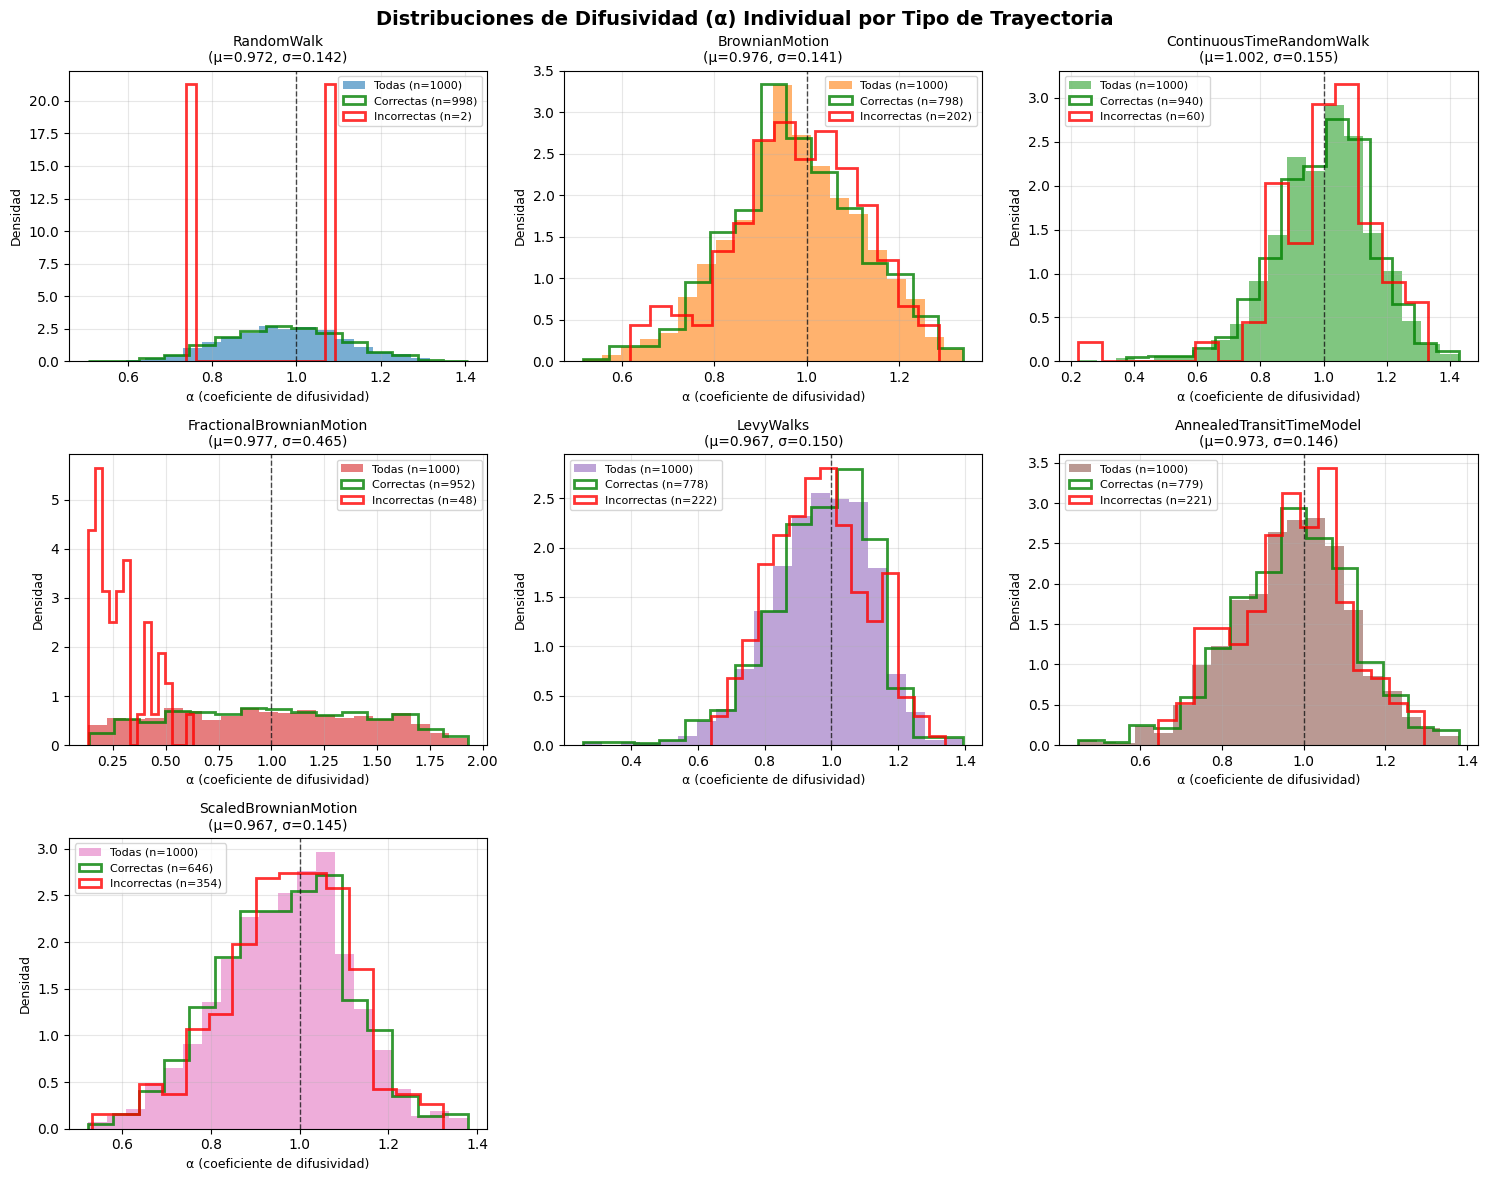


ANÁLISIS ESTADÍSTICO DE DIFUSIVIDAD INDIVIDUAL
📊 TABLA RESUMEN:
Tipo                      n    α_mean   α_std    Range    Acc%   Diff_α   Signif 
-------------------------------------------------------------------------------------
RandomWalk                1000    0.972    0.142    0.902   99.8    0.058 NO     
BrownianMotion            1000    0.976    0.141    0.823   79.8   -0.004 NO     
ContinuousTimeRandomWalk  1000    1.002    0.155    1.205   94.0   -0.007 NO     
FractionalBrownianMotion  1000    0.977    0.465    1.799   95.2    0.728 SÍ     
LevyWalks                 1000    0.967    0.150    1.138   77.8    0.005 NO     
AnnealedTransitTimeModel  1000    0.973    0.146    0.931   77.9    0.004 NO     
ScaledBrownianMotion      1000    0.967    0.145    0.856   64.6   -0.006 NO     

📈 INTERPRETACIONES:
- 'Diff_α': Diferencia entre α_promedio de predicciones correctas vs incorrectas
- 'Signif': Si la diferencia es estadísticamente significativa (p < 0.05)
- 'Range': Variab

In [ ]:
# Distribucions d'α per tipus de trajectòria
print("\n" + "="*60)
print("DISTRIBUCIONS D'α PER TIPUS DE TRAJECTÒRIA")
print("="*60)

# Crear histogrames per cada tipus de trajectòria
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

colors_hist = ['skyblue', 'orange', 'lightgreen', 'lightcoral', 'plum', 'tan', 'pink']

for i, (traj_type, data) in enumerate(individual_analysis.items()):
    if i < len(axes):
        ax = axes[i]
        
        alphas = data['alphas']
        is_correct = data['is_correct']
        
        # Histograma de totes les α
        ax.hist(alphas, bins=30, alpha=0.7, color=colors_hist[i % len(colors_hist)], 
                label=f'Totes (n={len(alphas)})', edgecolor='black', linewidth=0.5)
        
        # Histogrames separats per correctes i incorrectes
        correct_alphas = alphas[is_correct]
        incorrect_alphas = alphas[~is_correct]
        
        if len(correct_alphas) > 0:
            ax.hist(correct_alphas, bins=30, alpha=0.6, color='green', 
                    label=f'Correctes (n={len(correct_alphas)})', 
                    edgecolor='darkgreen', linewidth=1)
        
        if len(incorrect_alphas) > 0:
            ax.hist(incorrect_alphas, bins=30, alpha=0.6, color='red', 
                    label=f'Incorrectes (n={len(incorrect_alphas)})', 
                    edgecolor='darkred', linewidth=1)
        
        # Línia vertical a α = 1 (difusió normal teòrica)
        ax.axvline(x=1.0, color='black', linestyle='--', alpha=0.7, linewidth=2)
        
        # Estadístiques
        mean_alpha = np.mean(alphas)
        std_alpha = np.std(alphas)
        
        # Personalització
        ax.set_xlabel('α (coeficient de difusivitat)', fontsize=11)
        ax.set_ylabel('Densitat', fontsize=11)
        ax.set_title(f'{traj_type}\n(μ={mean_alpha:.3f}, σ={std_alpha:.3f})', fontsize=12, fontweight='bold')
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)

# Ocultar eixos sobrants
for j in range(len(individual_analysis), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribucions de Difusivitat (α) Individual per Tipus de Trajectòria', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


CORRELACIÓ α INDIVIDUAL vs PROBABILITAT DE CLASSIFICACIÓ CORRECTA


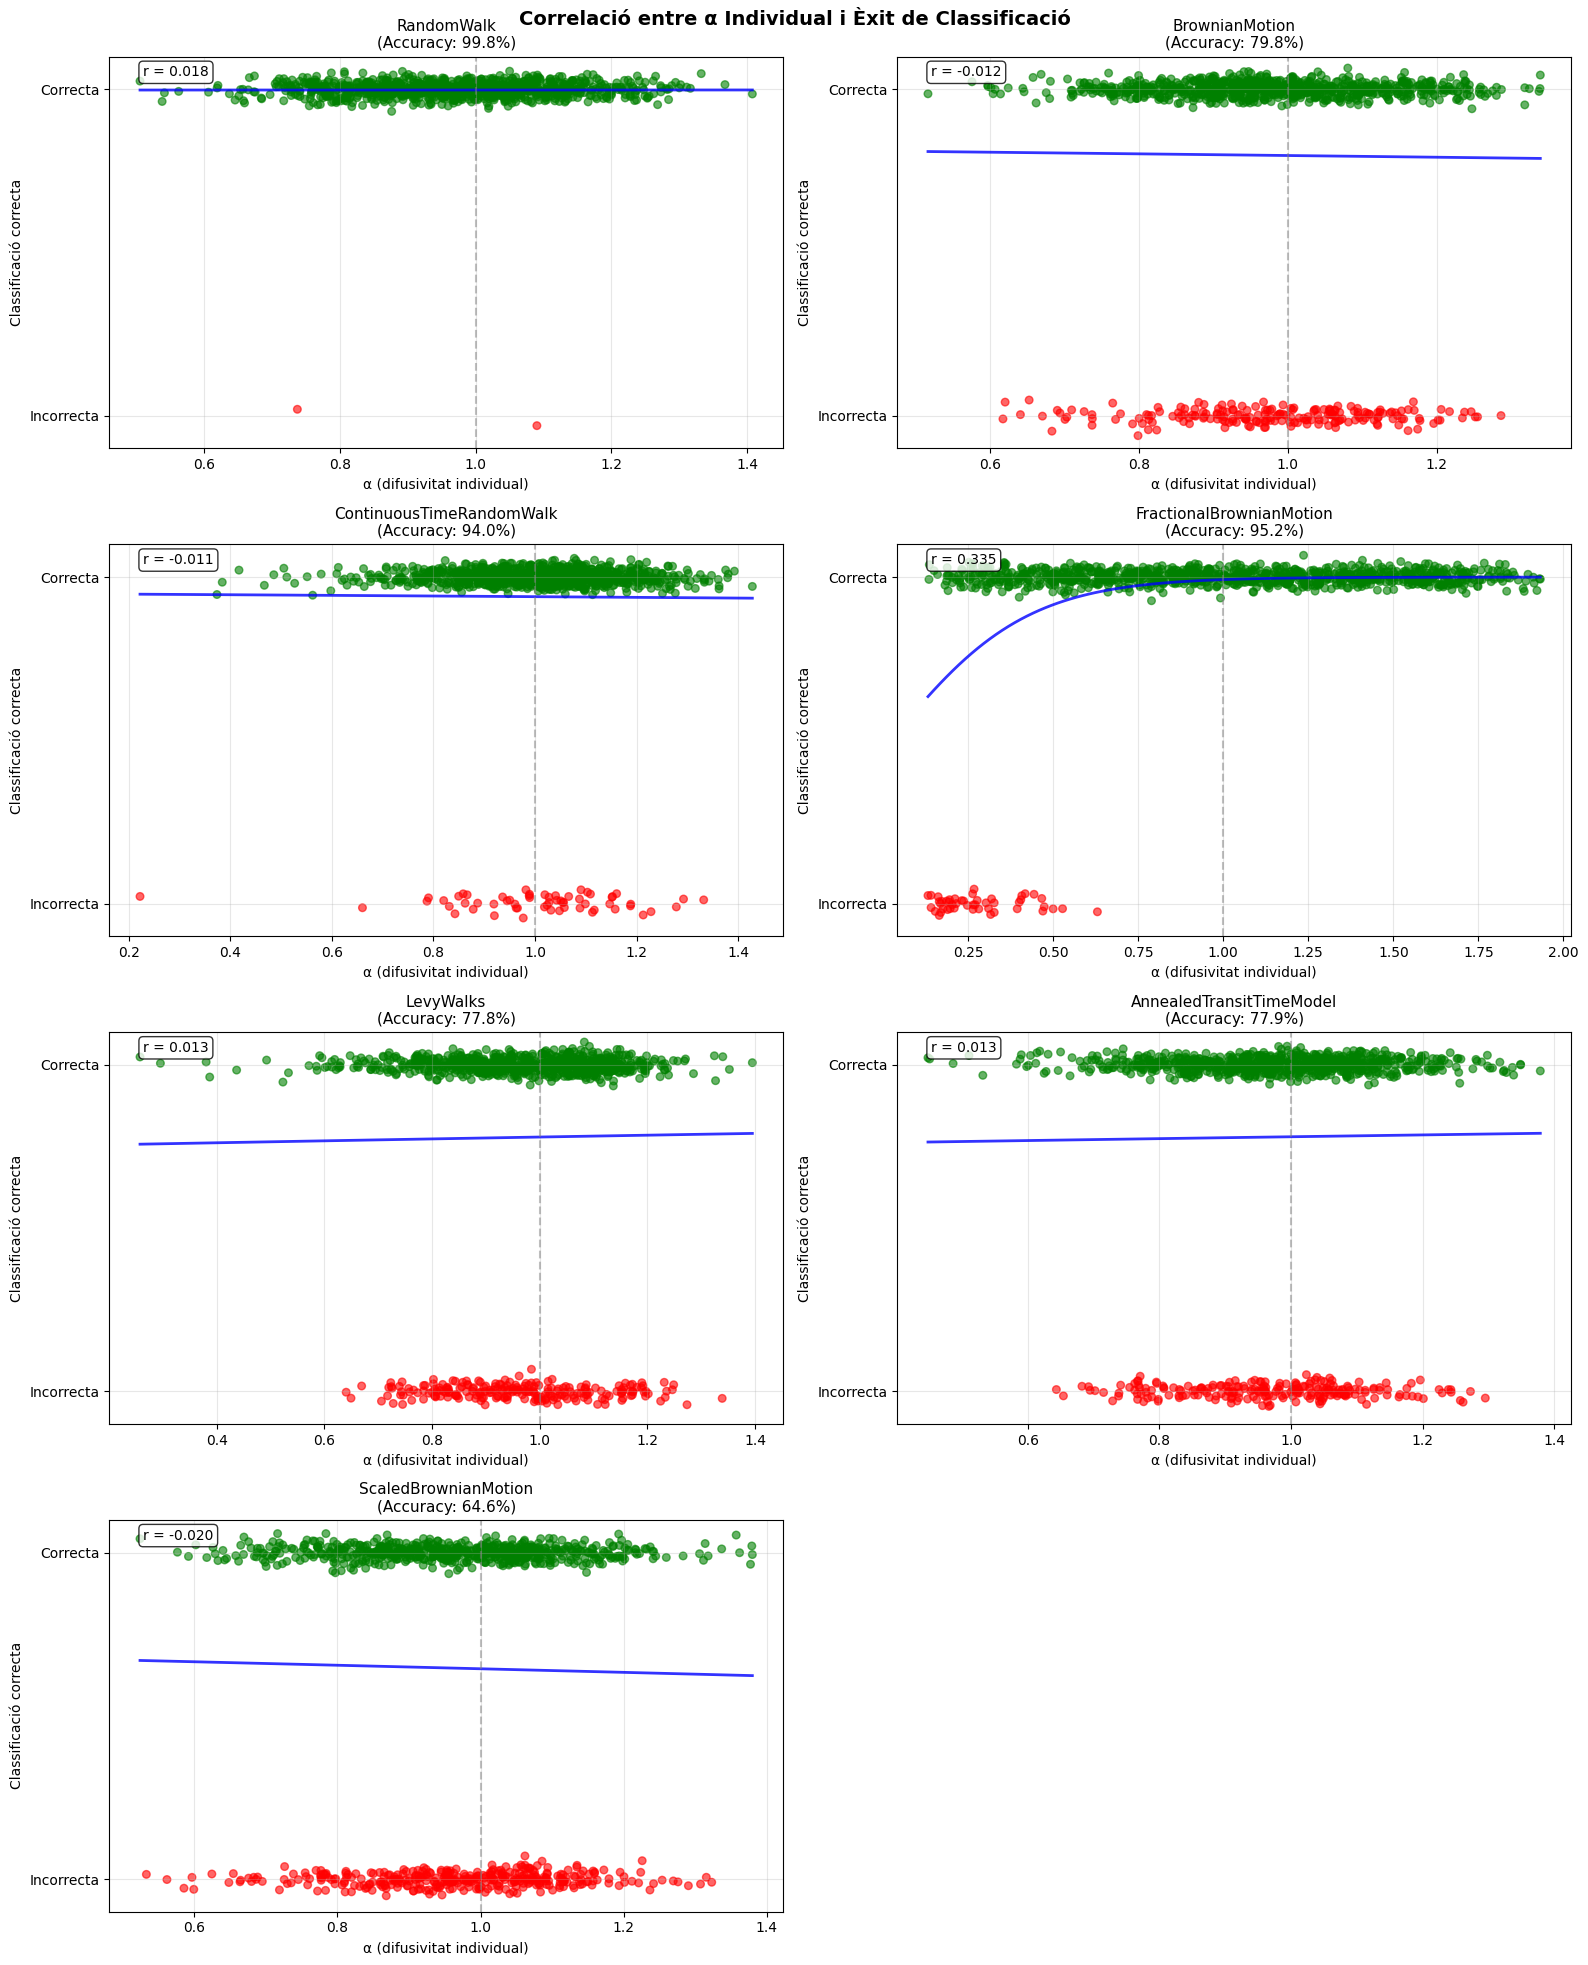


📊 CORRELACIONS INDIVIDUALS α vs ÈXIT DE CLASSIFICACIÓ:
Tipus de Trajectòria      Correlació   Interpretació  
-----------------------------------------------------------------
RandomWalk                       0.018 Molt feble positiva
BrownianMotion                  -0.012 Molt feble negativa
ContinuousTimeRandomWalk        -0.011 Molt feble negativa
FractionalBrownianMotion         0.335 Moderada positiva
LevyWalks                        0.013 Molt feble positiva
AnnealedTransitTimeModel         0.013 Molt feble positiva
ScaledBrownianMotion            -0.020 Molt feble negativa

🌐 ANÀLISI GLOBAL (TOTES LES TRAJECTÒRIES):
Correlació global α vs èxit: 0.0655

📈 ANÀLISI PER RANGS D'α:
Subdifusió      (0.0 ≤ α < 0.8): 1103 trajectòries, 84.1% accuracy
Difusió normal  (0.8 ≤ α < 1.2): 5216 trajectòries, 83.0% accuracy
Superdifusió    (1.2 ≤ α < 2.0):  681 trajectòries, 92.8% accuracy

💡 INTERPRETACIÓ:
- La correlació global de 0.065 indica que α individual NO influeix en la classificació

In [15]:
# Correlació individual: α específic vs probabilitat de classificació correcta
print("\n" + "="*70)
print("CORRELACIÓ α INDIVIDUAL vs PROBABILITAT DE CLASSIFICACIÓ CORRECTA")
print("="*70)

# Crear scatter plot per cada tipus mostrant α individual vs èxit de classificació
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

individual_correlations = {}

for i, (traj_type, data) in enumerate(individual_analysis.items()):
    if i < len(axes):
        ax = axes[i]
        
        alphas = data['alphas']
        is_correct = data['is_correct']
        
        # Scatter plot amb jitter en y per visualització
        y_jitter = is_correct.astype(float) + np.random.normal(0, 0.02, len(is_correct))
        
        # Colors diferents per correctes/incorrectes
        colors = ['red' if not correct else 'green' for correct in is_correct]
        ax.scatter(alphas, y_jitter, c=colors, alpha=0.6, s=30)
        
        # Línia de tendència si hi ha variació
        if len(np.unique(alphas)) > 1:
            # Regressió logística per probabilitat
            from sklearn.linear_model import LogisticRegression
            from sklearn.preprocessing import StandardScaler
            
            # Preparar dades
            X = alphas.reshape(-1, 1)
            y = is_correct.astype(int)
            
            # Ajustar model si hi ha variació en les prediccions
            if len(np.unique(y)) > 1:
                lr_model = LogisticRegression()
                lr_model.fit(X, y)
                
                # Generar corba de probabilitat
                alpha_range = np.linspace(alphas.min(), alphas.max(), 100).reshape(-1, 1)
                prob_correct = lr_model.predict_proba(alpha_range)[:, 1]
                ax.plot(alpha_range.flatten(), prob_correct, 'blue', linewidth=2, alpha=0.8)
                
                # Calcular correlació punt-biserial (equivalent a Pearson per binari)
                correlation = np.corrcoef(alphas, is_correct.astype(float))[0, 1]
                individual_correlations[traj_type] = correlation
                
                # R² del model logístic
                log_likelihood = lr_model.score(X, y)
                
                ax.text(0.05, 0.95, f'r = {correlation:.3f}', 
                       transform=ax.transAxes, fontsize=10, 
                       bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
            else:
                individual_correlations[traj_type] = np.nan
        else:
            individual_correlations[traj_type] = np.nan
        
        # Personalització
        ax.set_ylim(-0.1, 1.1)
        ax.set_xlabel('α (difusivitat individual)', fontsize=10)
        ax.set_ylabel('Classificació correcta', fontsize=10)
        ax.set_title(f'{traj_type}\n(Accuracy: {np.mean(is_correct)*100:.1f}%)', fontsize=11)
        ax.grid(True, alpha=0.3)
        ax.set_yticks([0, 1])
        ax.set_yticklabels(['Incorrecta', 'Correcta'])
        
        # Línia vertical a α = 1
        ax.axvline(x=1.0, color='gray', linestyle='--', alpha=0.5)

# Ocultar eixos sobrants
for j in range(len(individual_analysis), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Correlació entre α Individual i Èxit de Classificació', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Resum de correlacions individuals
print("\n📊 CORRELACIONS INDIVIDUALS α vs ÈXIT DE CLASSIFICACIÓ:")
print("="*65)
print(f"{'Tipus de Trajectòria':25} {'Correlació':12} {'Interpretació':15}")
print("-" * 65)

for traj_type, corr in individual_correlations.items():
    if not np.isnan(corr):
        if abs(corr) > 0.5:
            interpretation = "Forta"
        elif abs(corr) > 0.3:
            interpretation = "Moderada"
        elif abs(corr) > 0.1:
            interpretation = "Feble"
        else:
            interpretation = "Molt feble"
        
        direction = "positiva" if corr > 0 else "negativa"
        interpretation += f" {direction}"
    else:
        interpretation = "No calculable"
        corr = 0
    
    print(f"{traj_type:25} {corr:12.3f} {interpretation:15}")

# Anàlisi global de totes les trajectòries juntes
print(f"\n🌐 ANÀLISI GLOBAL (TOTES LES TRAJECTÒRIES):")
print("="*50)

all_alphas = []
all_correct = []
all_types = []

for traj_type, data in individual_analysis.items():
    all_alphas.extend(data['alphas'])
    all_correct.extend(data['is_correct'])
    all_types.extend([traj_type] * len(data['alphas']))

all_alphas = np.array(all_alphas)
all_correct = np.array(all_correct)

# Correlació global
global_correlation = np.corrcoef(all_alphas, all_correct.astype(float))[0, 1]
print(f"Correlació global α vs èxit: {global_correlation:.4f}")

# Anàlisi per rangs d'α
alpha_ranges = [
    (0.0, 0.8, "Subdifusió"),
    (0.8, 1.2, "Difusió normal"),
    (1.2, 2.0, "Superdifusió")
]

print(f"\n📈 ANÀLISI PER RANGS D'α:")
for min_alpha, max_alpha, label in alpha_ranges:
    mask = (all_alphas >= min_alpha) & (all_alphas < max_alpha)
    if np.any(mask):
        subset_correct = all_correct[mask]
        n_trajectories = np.sum(mask)
        accuracy = np.mean(subset_correct) * 100
        print(f"{label:15} ({min_alpha:.1f} ≤ α < {max_alpha:.1f}): {n_trajectories:4d} trajectòries, {accuracy:.1f}% accuracy")

print(f"\n💡 INTERPRETACIÓ:")
print(f"- La correlació global de {global_correlation:.3f} indica que α individual {'SÍ' if abs(global_correlation) > 0.1 else 'NO'} influeix en la classificació")
print(f"- El model {'podria estar' if abs(global_correlation) > 0.2 else 'probablement no està'} usant característiques relacionades amb la difusivitat")
print(f"- La variabilitat d'α dins de cada tipus explica part dels errors de classificació")